In [1]:
import sys
print(sys.executable)


c:\Users\Neha\anaconda3\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

print("\nALL PACKAGES WORKING ✅")

NumPy: 2.3.5
Pandas: 2.3.3
Matplotlib: 3.10.6
Seaborn: 0.13.2
Scikit-learn: 1.7.2
Joblib: 1.5.2

ALL PACKAGES WORKING ✅


In [3]:
df = pd.read_csv("../data/emotions/fer2013.csv")

df.head()

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


In [4]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (35887, 3)
Number of Rows: 35887
Number of Columns: 3


In [5]:
print("Data Types:")
print(df.dtypes)

Data Types:
emotion     int64
pixels     object
Usage      object
dtype: object


In [6]:
print(df.isnull().sum())

emotion    0
pixels     0
Usage      0
dtype: int64


Observation: The distribution of mean pixel intensity shows how overall brightness varies across the facial images. Most images are concentrated within a particular intensity range, while relatively few images have very low or very high average brightness.

In [7]:
# Create numerical pixel features for EDA

pixel_values = df["pixels"].str.split().apply(
    lambda x: np.array(x, dtype=np.int16)
)

df["pixel_mean"] = pixel_values.apply(np.mean)
df["pixel_std"] = pixel_values.apply(np.std)
df["pixel_min"] = pixel_values.apply(np.min)
df["pixel_max"] = pixel_values.apply(np.max)

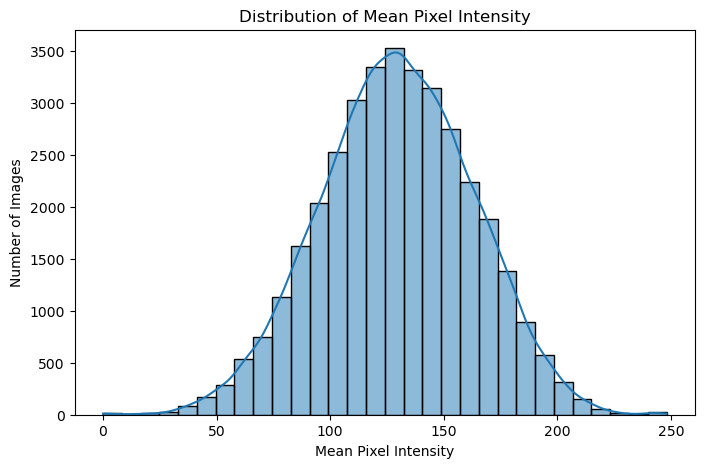

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(df["pixel_mean"], bins=30, kde=True)

plt.title("Distribution of Mean Pixel Intensity")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")

plt.show()

Observation: Pixel standard deviation represents the variation in intensity within an image. Higher values indicate greater contrast or variation between darker and brighter regions of the face.

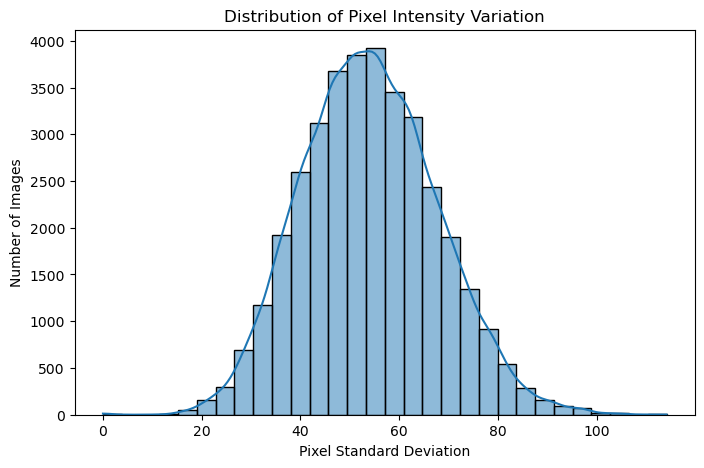

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df["pixel_std"], bins=30, kde=True)

plt.title("Distribution of Pixel Intensity Variation")
plt.xlabel("Pixel Standard Deviation")
plt.ylabel("Number of Images")

plt.show()

Observation: The emotion classes are not perfectly balanced. Some emotions contain considerably more samples than others. Therefore, accuracy alone may not fully represent model performance, and weighted F1-score will also be used for evaluation.

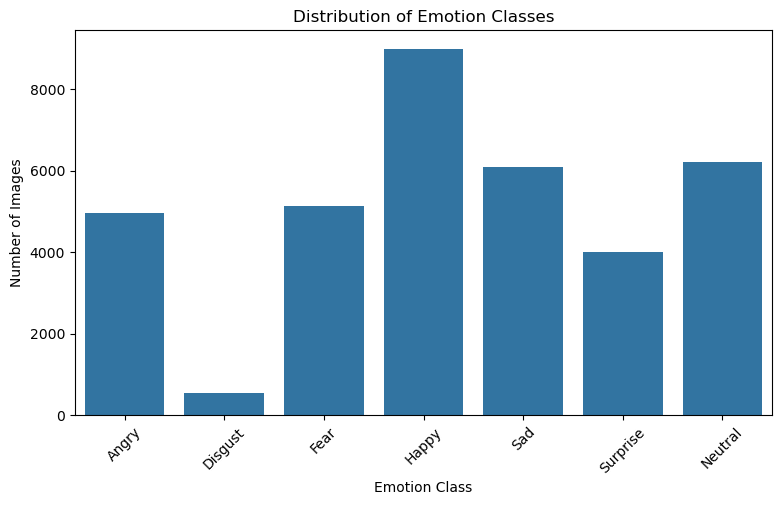

In [10]:
emotion_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="emotion")

plt.title("Distribution of Emotion Classes")
plt.xlabel("Emotion Class")
plt.ylabel("Number of Images")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

Observation: The sample images show visible differences in facial expressions across the seven emotion classes. For example, happy images generally show smiling expressions, while angry and sad images have different facial configurations. However, some expressions can appear visually similar, which makes emotion classification a challenging task.

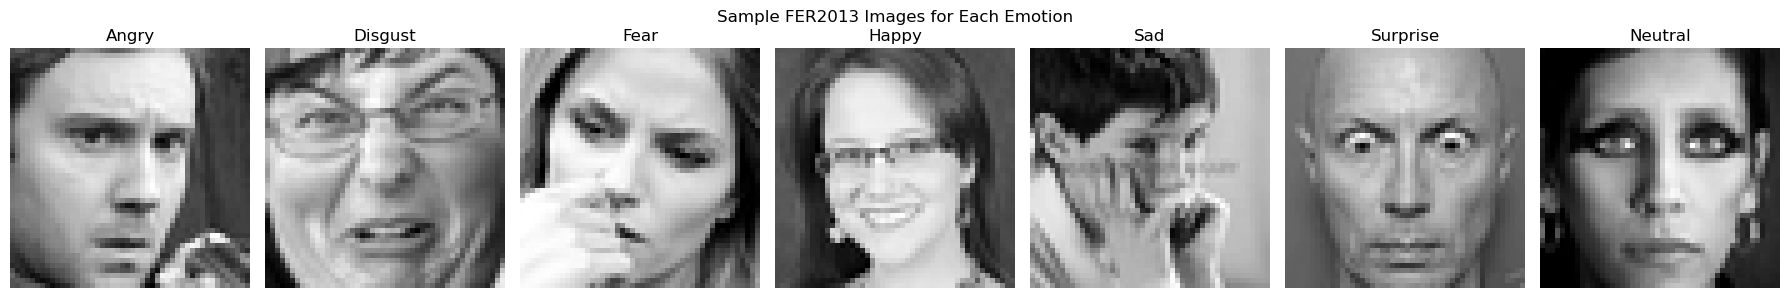

In [11]:
# Display one image from each emotion class

fig, axes = plt.subplots(1, 7, figsize=(18, 3))

for emotion_id in range(7):
    # Get the first image belonging to this emotion
    row = df[df["emotion"] == emotion_id].iloc[0]

    # Convert pixel string into a 48x48 image
    image = np.array(row["pixels"].split(), dtype=np.uint8).reshape(48, 48)

    axes[emotion_id].imshow(image, cmap="gray")
    axes[emotion_id].set_title(emotion_names[emotion_id])
    axes[emotion_id].axis("off")

plt.suptitle("Sample FER2013 Images for Each Emotion")
plt.tight_layout()
plt.show()

Observation: The correlation heatmap shows the relationships among the emotion label and the extracted pixel-statistical features. The pixel statistics also show relationships with one another because they are calculated from the same image intensity values. The correlations with the emotion label are relatively limited, indicating that simple pixel statistics alone may not be sufficient to distinguish all facial expressions.

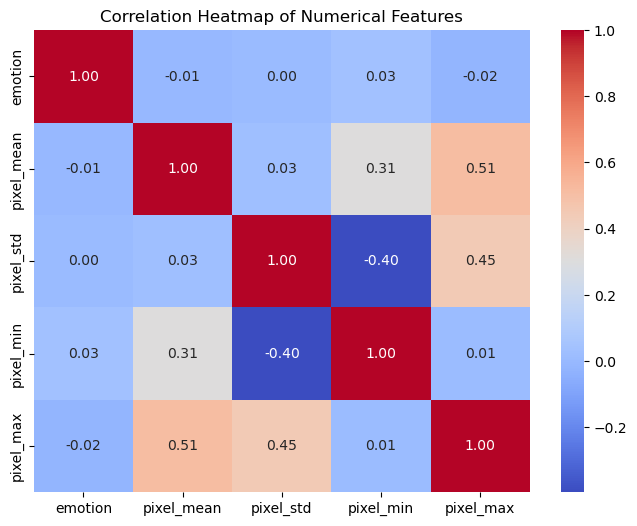

In [12]:
# Correlation heatmap

correlation_data = df[
    ["emotion", "pixel_mean", "pixel_std", "pixel_min", "pixel_max"]
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Observation: The boxplot shows how the average brightness of facial images varies across emotion classes. Some emotions have slightly different median pixel intensities, but there is considerable overlap between classes. This suggests that mean brightness alone is not enough to reliably separate the emotions.

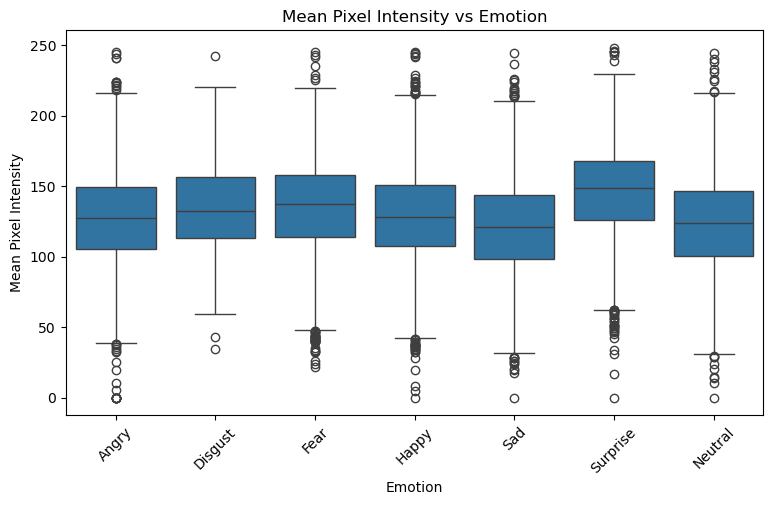

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="emotion",
    y="pixel_mean"
)

plt.title("Mean Pixel Intensity vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Mean Pixel Intensity")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

Observation: The plot shows the variation in pixel intensity for different emotion classes. Although some classes have different distributions of pixel variation, there is substantial overlap among the classes. Therefore, more informative image features or the complete pixel representation are required for effective emotion classification.

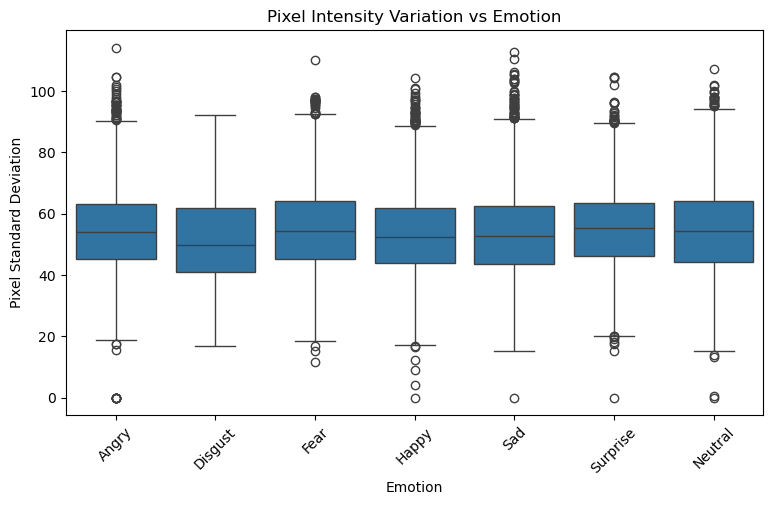

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="emotion",
    y="pixel_std"
)

plt.title("Pixel Intensity Variation vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Pixel Standard Deviation")
plt.xticks(
    ticks=range(7),
    labels=[emotion_names[i] for i in range(7)],
    rotation=45
)

plt.show()

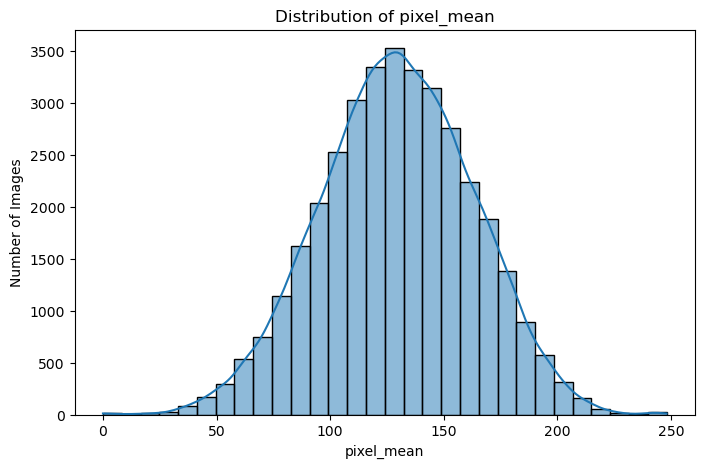

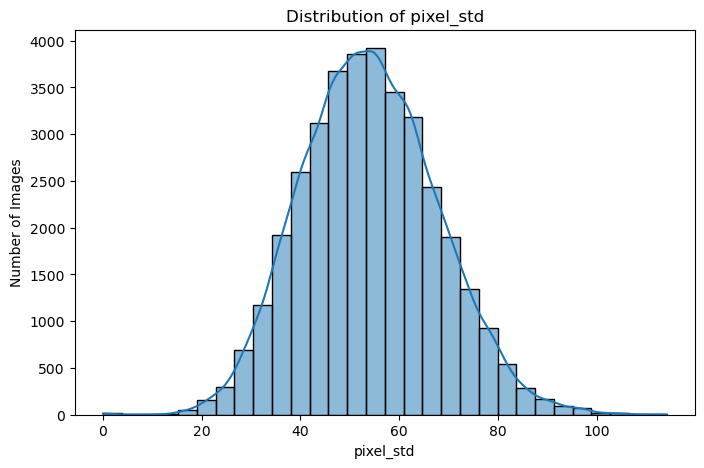

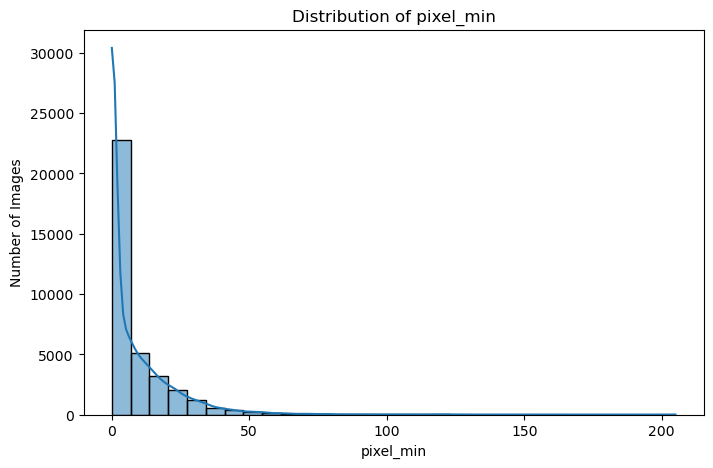

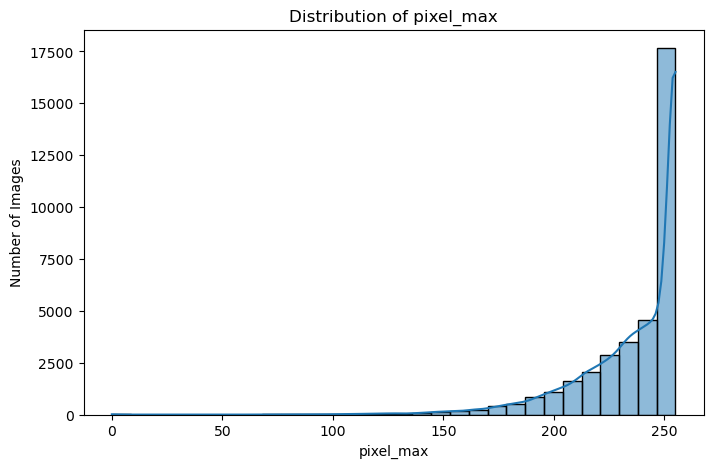

In [15]:
features = ["pixel_mean", "pixel_std", "pixel_min", "pixel_max"]

for feature in features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[feature],
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Images")

    plt.show()

B1

Missing Value Treatment: No missing values were found in the dataset. Therefore, no imputation or row removal was necessary.

In [16]:
missing_values = df.isnull().sum()

print("Missing values before treatment:")
print(missing_values)

if missing_values.sum() == 0:
    print("\nNo missing values found. No imputation is required.")
else:
    df = df.dropna()
    print("\nMissing rows were removed.")

Missing values before treatment:
emotion       0
pixels        0
Usage         0
pixel_mean    0
pixel_std     0
pixel_min     0
pixel_max     0
dtype: int64

No missing values found. No imputation is required.


Duplicate Treatment: The dataset contained 1,234 exact duplicate rows. These rows were removed using drop_duplicates() to prevent identical observations from receiving additional weight during model training.

In [17]:
duplicates_before = df.duplicated().sum()

print("Duplicate rows before treatment:", duplicates_before)

df = df.drop_duplicates()

duplicates_after = df.duplicated().sum()

print("Duplicate rows after treatment:", duplicates_after)
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows before treatment: 1234
Duplicate rows after treatment: 0
Dataset shape after removing duplicates: (34653, 7)


Outlier Treatment: Pixel values were first checked for invalid values outside the permissible 0–255 grayscale range. Statistical outliers in image-level pixel statistics were also examined using the IQR method. Extreme pixel statistics were retained when they represented valid facial images rather than erroneous observations.

In [18]:
# Convert pixel strings into numerical pixel arrays

pixel_values = df["pixels"].str.split().apply(
    lambda x: np.array(x, dtype=np.int16)
)

# --------------------------------------------------
# 1. Check for invalid pixel values
# --------------------------------------------------

invalid_pixels = pixel_values.apply(
    lambda x: np.any((x < 0) | (x > 255))
)

print("Rows containing invalid pixel values:", invalid_pixels.sum())


# --------------------------------------------------
# 2. Statistical outlier detection using IQR
# --------------------------------------------------

Q1 = df["pixel_mean"].quantile(0.25)
Q3 = df["pixel_mean"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["pixel_mean"] < lower) |
    (df["pixel_mean"] > upper)
]

print("Pixel mean statistical outliers:", len(outliers))


# --------------------------------------------------
# 3. Treat invalid pixel values
# --------------------------------------------------

if invalid_pixels.sum() == 0:
    print("No invalid pixel values found.")
else:
    df = df.loc[~invalid_pixels].copy()
    print("Rows with invalid pixel values were removed.")


print("Final dataset shape:", df.shape)

Rows containing invalid pixel values: 0
Pixel mean statistical outliers: 141
No invalid pixel values found.
Final dataset shape: (34653, 7)


Observation: The data was split into 80% training and 20% testing using stratified sampling. Pixel values were normalized from 0–255 to 0–1.

Create X and y

In [19]:
# Input features
X = np.vstack(
    df["pixels"].str.split().apply(
        lambda x: np.array(x, dtype=np.float32)
    )
)

# Target
y = df["emotion"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (34653, 2304)
y shape: (34653,)


Train-Test Split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (27722, 2304)
Testing data : (6931, 2304)


Scale the pixel values

In [21]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training range:", X_train.min(), "to", X_train.max())
print("Testing range :", X_test.min(), "to", X_test.max())

Training range: 0.0 to 1.0
Testing range : 0.0 to 1.0


Observation: Four numerical features were engineered from the pixel data to represent image brightness and intensity variation.

In [22]:
# Create numerical pixel features for EDA

df["pixel_mean"] = pixel_values.apply(np.mean)
df["pixel_std"] = pixel_values.apply(np.std)
df["pixel_min"] = pixel_values.apply(np.min)
df["pixel_max"] = pixel_values.apply(np.max)

df[["pixel_mean", "pixel_std", "pixel_min", "pixel_max"]].head()

,pixel_mean,pixel_std,pixel_min,pixel_max
0,117.592882,50.735357,11,210
1,126.971354,40.854364,0,219
2,160.814236,74.711745,0,255
3,130.503472,59.357461,12,235
4,97.900174,70.166311,0,241


Justification: These features provide useful information about the brightness and contrast of facial images and can help analyze differences between emotion classes.

 Logistic Regression

In [23]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# Reduce 2304 pixels to 100 features
pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("Reduced features :", X_train_pca.shape[1])

# Logistic Regression
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=200,
    random_state=42
)

logistic_model.fit(X_train_pca, y_train)

y_pred_lr = logistic_model.predict(X_test_pca)

print("Logistic Regression training completed!")
print("Predictions:", y_pred_lr[:10])

Original features: 2304
Reduced features : 100
Logistic Regression training completed!
Predictions: [5 3 4 4 3 6 2 4 3 3]


In [64]:
# Get Logistic Regression coefficients

lr_coefficients = logistic_model.coef_

print("Coefficient shape:", lr_coefficients.shape)

Coefficient shape: (7, 100)


In [65]:
import numpy as np

for i, emotion in enumerate(emotion_names):

    # Get absolute coefficient values
    coefficient_strength = np.abs(lr_coefficients[i])

    # Find top 5 components
    top_components = np.argsort(
        coefficient_strength
    )[-5:][::-1]

    print("\n", emotion)
    print("Top PCA components:", top_components + 1)
    print("Coefficients:",
          lr_coefficients[i][top_components])


 Angry
Top PCA components: [65 83 47 51 76]
Coefficients: [ 0.21515322 -0.18098922 -0.1682659   0.15100214  0.1490173 ]

 Disgust
Top PCA components: [ 93  78  67 100  95]
Coefficients: [-0.47130698 -0.46565101 -0.43398805  0.41059472 -0.38788768]

 Fear
Top PCA components: [46 63 50 28 23]
Coefficients: [ 0.14133579 -0.14083958  0.13613689 -0.13607237 -0.13377285]

 Happy
Top PCA components: [23 49 65 51 67]
Coefficients: [ 0.53278044 -0.30767375 -0.28636242 -0.28271036  0.28157364]

 Sad
Top PCA components: [30 17 51 49 19]
Coefficients: [-0.21341416 -0.16615977  0.12513995  0.10758952 -0.10634326]

 Surprise
Top PCA components: [14 36 33 23 93]
Coefficients: [ 0.44044859 -0.40653271 -0.37903047 -0.35870065  0.35251247]

 Neutral
Top PCA components: [ 98  91  76  22 100]
Coefficients: [-0.23793185  0.23153022 -0.21189994 -0.16844451 -0.16423099]


In [66]:
import numpy as np

happy_coefficient = 0.53278044

odds_ratio = np.exp(happy_coefficient)

print("Odds ratio:", odds_ratio)

Odds ratio: 1.7036626611499535


In [24]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Calculate weighted F1-score
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted")

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Weighted F1:", lr_f1)

Logistic Regression Accuracy: 0.36517097099985574
Logistic Regression Weighted F1: 0.3338712836969175


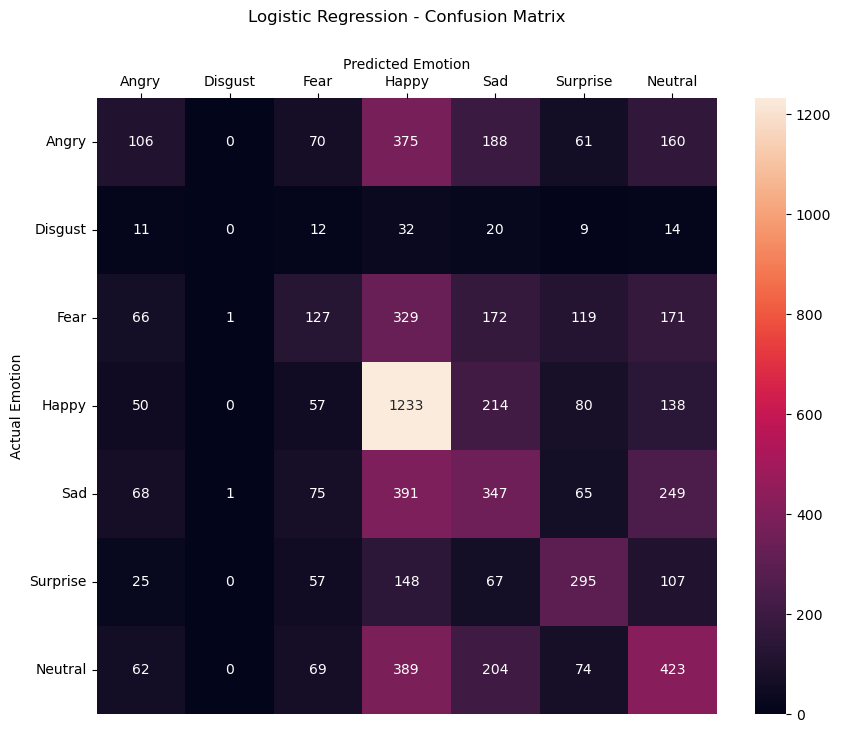

In [25]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

# Move predicted class names to top
plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

# Put "Predicted Emotion" at the TOP
plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")
plt.gca().xaxis.label.set_visible(True)

plt.ylabel("Actual Emotion")

plt.title("Logistic Regression - Confusion Matrix", pad=55)

plt.show()

In [26]:
from sklearn.metrics import classification_report

print("Logistic Regression - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

Logistic Regression - Classification Report

              precision    recall  f1-score   support

       Angry       0.27      0.11      0.16       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.27      0.13      0.17       985
       Happy       0.43      0.70      0.53      1772
         Sad       0.29      0.29      0.29      1196
    Surprise       0.42      0.42      0.42       699
     Neutral       0.34      0.35      0.34      1221

    accuracy                           0.37      6931
   macro avg       0.29      0.28      0.27      6931
weighted avg       0.34      0.37      0.33      6931



### Logistic Regression Coefficient and Odds Interpretation

The Logistic Regression coefficients show how the PCA components influence each emotion class. A positive coefficient increases the tendency toward that emotion, while a negative coefficient decreases it. The magnitude of the coefficient indicates the strength of the influence.

For example, for the Happy class, PC23 has a coefficient of approximately +0.533, indicating a relatively strong positive contribution toward the Happy class. PC49 has a coefficient of approximately -0.308, indicating a negative contribution.

The coefficient of PC23 corresponds to an odds ratio of approximately 1.70 using exp(coefficient). Thus, a one-unit increase in PC23 multiplies the odds of predicting the Happy class by approximately 1.70, while keeping other PCA components constant.

Since PCA was used, these coefficients represent PCA components rather than individual facial pixels.

Train KNN and make predictions

### KNN Distance Metric Discussion

K-Nearest Neighbors (KNN) classifies a new image by finding the training samples that are closest to it.

In this project, KNN uses the default **Minkowski distance with p = 2**, which is equivalent to **Euclidean distance**.

Euclidean distance measures the straight-line distance between two data points. Since the pixel values were normalized before PCA, differences in feature scale are reduced.

Other distance metrics that can be used with KNN include:

- **Euclidean distance (p = 2):** Measures straight-line distance and is commonly used for continuous numerical features.
- **Manhattan distance (p = 1):** Measures the sum of absolute differences between features.
- **Minkowski distance:** A general distance metric where different values of p produce different distance measures.

Euclidean distance was used because the FER2013 data consists of continuous numerical pixel features, and it provides a standard way to measure similarity between images in the PCA feature space.

Since KNN is a distance-based algorithm, feature scaling is important. Therefore, the pixel values were normalized before applying PCA and KNN.

In [61]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

# Values of k to test
k_values = [3, 5, 7, 9]

knn_results = []

# Try different values of k
for k in k_values:

    print("Training KNN with k =", k)

    # Create KNN model
    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )

    # Train the model
    knn_model.fit(X_train_pca, y_train)

    # Make predictions
    y_pred = knn_model.predict(X_test_pca)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store result
    knn_results.append({
        "k": k,
        "Accuracy": accuracy
    })


# Create comparison table
knn_tuning = pd.DataFrame(knn_results)

print("\nKNN Tuning Results:")
knn_tuning

Training KNN with k = 3
Training KNN with k = 5
Training KNN with k = 7
Training KNN with k = 9

KNN Tuning Results:


,k,Accuracy
0,3,0.324917
1,5,0.326360
2,7,0.332420
3,9,0.328813


In [62]:
# Find the k with the highest accuracy

best_k = int(
    knn_tuning.loc[
        knn_tuning["Accuracy"].idxmax(),
        "k"
    ]
)

print("Best k:", best_k)

Best k: 7


In [28]:
from sklearn.metrics import accuracy_score, f1_score

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

print("KNN Accuracy:", knn_accuracy)
print("KNN Weighted F1:", knn_f1)

KNN Accuracy: 0.3263598326359833
KNN Weighted F1: 0.3216314520096285


In [29]:
from sklearn.metrics import classification_report

print("KNN - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

KNN - Classification Report

              precision    recall  f1-score   support

       Angry       0.26      0.27      0.26       960
     Disgust       0.16      0.20      0.18        98
        Fear       0.28      0.27      0.27       985
       Happy       0.39      0.50      0.44      1772
         Sad       0.29      0.21      0.24      1196
    Surprise       0.45      0.34      0.39       699
     Neutral       0.29      0.29      0.29      1221

    accuracy                           0.33      6931
   macro avg       0.30      0.30      0.30      6931
weighted avg       0.32      0.33      0.32      6931



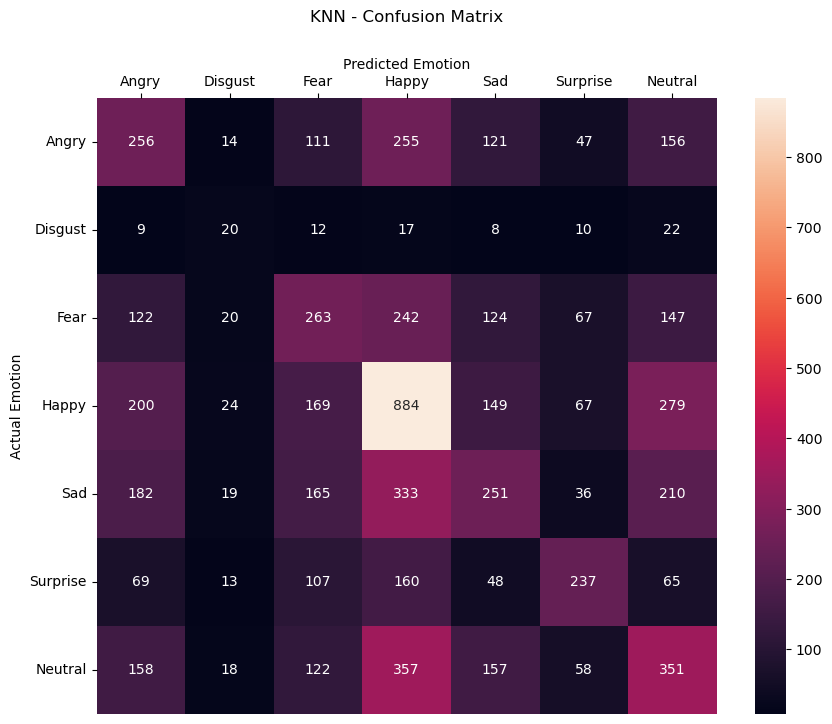

In [30]:
from sklearn.metrics import confusion_matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "KNN - Confusion Matrix",
    pad=55
)

plt.show()

Observation: KNN classified the seven emotion classes with moderate performance. The confusion matrix shows that some visually similar emotions were frequently misclassified.

Gaussian Naive Bayes

### Gaussian Naive Bayes — Conditional Independence Assumption

Gaussian Naive Bayes assumes that the input features are conditionally independent given the target class.

This means that once the emotion class is known, the model assumes that each feature contributes independently to the prediction.

For example, if the emotion is "Happy", Gaussian Naive Bayes assumes that the values of the different features can be treated as independent when calculating the probability of the Happy class.

This assumption is called "naive" because it is a strong simplification. In image data, pixels and extracted features can be related to each other, so they may not actually be independent.

In this project, PCA was applied before classification. PCA transforms the original pixel features into principal components and reduces correlation between the components. This can make the independence assumption more reasonable, although the components are not guaranteed to be completely independent.

Therefore, Gaussian Naive Bayes is simple and computationally efficient, but its performance can be affected when the input features have strong dependencies.

In [31]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train_pca, y_train)

# Make predictions
y_pred_gnb = gnb_model.predict(X_test_pca)

print("Gaussian Naive Bayes training completed!")
print("Predictions:", y_pred_gnb[:10])

Gaussian Naive Bayes training completed!
Predictions: [5 6 1 0 3 6 2 2 2 4]


In [32]:
from sklearn.metrics import accuracy_score, f1_score

gnb_accuracy = accuracy_score(y_test, y_pred_gnb)

gnb_f1 = f1_score(
    y_test,
    y_pred_gnb,
    average="weighted"
)

print("Gaussian Naive Bayes Accuracy:", gnb_accuracy)
print("Gaussian Naive Bayes Weighted F1:", gnb_f1)

Gaussian Naive Bayes Accuracy: 0.31842446977348143
Gaussian Naive Bayes Weighted F1: 0.301252878009798


In [33]:
from sklearn.metrics import classification_report

print("Gaussian Naive Bayes - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_gnb,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ]
    )
)

Gaussian Naive Bayes - Classification Report

              precision    recall  f1-score   support

       Angry       0.24      0.14      0.18       960
     Disgust       0.05      0.09      0.07        98
        Fear       0.19      0.20      0.20       985
       Happy       0.38      0.62      0.47      1772
         Sad       0.30      0.18      0.22      1196
    Surprise       0.44      0.32      0.37       699
     Neutral       0.32      0.27      0.30      1221

    accuracy                           0.32      6931
   macro avg       0.28      0.26      0.26      6931
weighted avg       0.31      0.32      0.30      6931



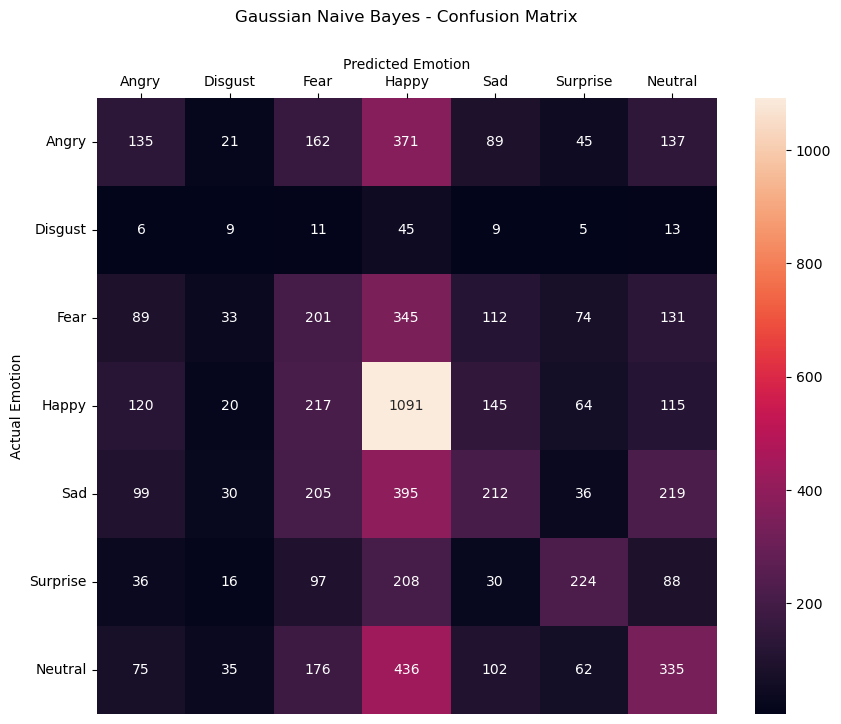

In [34]:
from sklearn.metrics import confusion_matrix

cm_gnb = confusion_matrix(y_test, y_pred_gnb)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_gnb,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "Gaussian Naive Bayes - Confusion Matrix",
    pad=55
)

plt.show()

Observation: Gaussian Naive Bayes showed lower classification performance compared with Logistic Regression. Several emotion classes were confused, mainly because the model assumes conditional independence between features.

Decision Tree Classifier

In [51]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

depths = [5, 10, 15, 20]

dt_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    dt_results.append({
        "max_depth": depth,
        "Accuracy": accuracy
    })

dt_tuning = pd.DataFrame(dt_results)

print("Decision Tree max_depth tuning results:")
print(dt_tuning)

Decision Tree max_depth tuning results:
   max_depth  Accuracy
0          5  0.296061
1         10  0.288270
2         15  0.271678
3         20  0.271678


In [52]:
depths = [5, 10, 15, 20]

dt_results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    dt_results.append({
        "max_depth": depth,
        "Accuracy": accuracy
    })

dt_tuning = pd.DataFrame(dt_results)

print("Decision Tree max_depth tuning results:")
print(dt_tuning)

Decision Tree max_depth tuning results:
   max_depth  Accuracy
0          5  0.296061
1         10  0.288270
2         15  0.271678
3         20  0.271678


In [54]:
best_depth = int(
    dt_tuning.loc[
        dt_tuning["Accuracy"].idxmax(),
        "max_depth"
    ]
)

print("Best max_depth:", best_depth)

Best max_depth: 5


In [55]:
dt_model = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

dt_model.fit(X_train_pca, y_train)

y_pred_dt = dt_model.predict(X_test_pca)

print("Final Decision Tree training completed!")
print("Predictions:", y_pred_dt[:10])

Final Decision Tree training completed!
Predictions: [5 3 4 3 6 2 3 5 3 3]


In [56]:
from sklearn.metrics import accuracy_score, f1_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="weighted"
)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Weighted F1:", dt_f1)

Decision Tree Accuracy: 0.29606117443370367
Decision Tree Weighted F1: 0.24626374306376658


In [63]:
from sklearn.metrics import classification_report

print("Decision Tree - Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=[
            "Angry",
            "Disgust",
            "Fear",
            "Happy",
            "Sad",
            "Surprise",
            "Neutral"
        ],
        zero_division=0
    )
)

Decision Tree - Classification Report

              precision    recall  f1-score   support

       Angry       0.20      0.00      0.01       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.20      0.14      0.17       985
       Happy       0.34      0.69      0.45      1772
         Sad       0.26      0.14      0.18      1196
    Surprise       0.30      0.27      0.28       699
     Neutral       0.25      0.27      0.26      1221

    accuracy                           0.30      6931
   macro avg       0.22      0.22      0.19      6931
weighted avg       0.26      0.30      0.25      6931



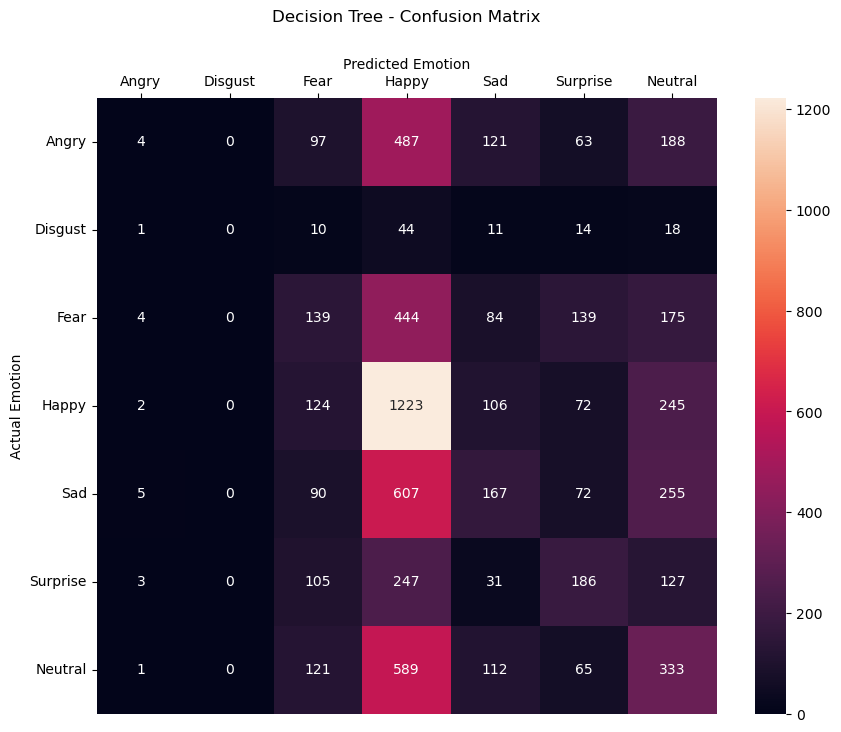

In [58]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "Decision Tree - Confusion Matrix",
    pad=55
)

plt.show()

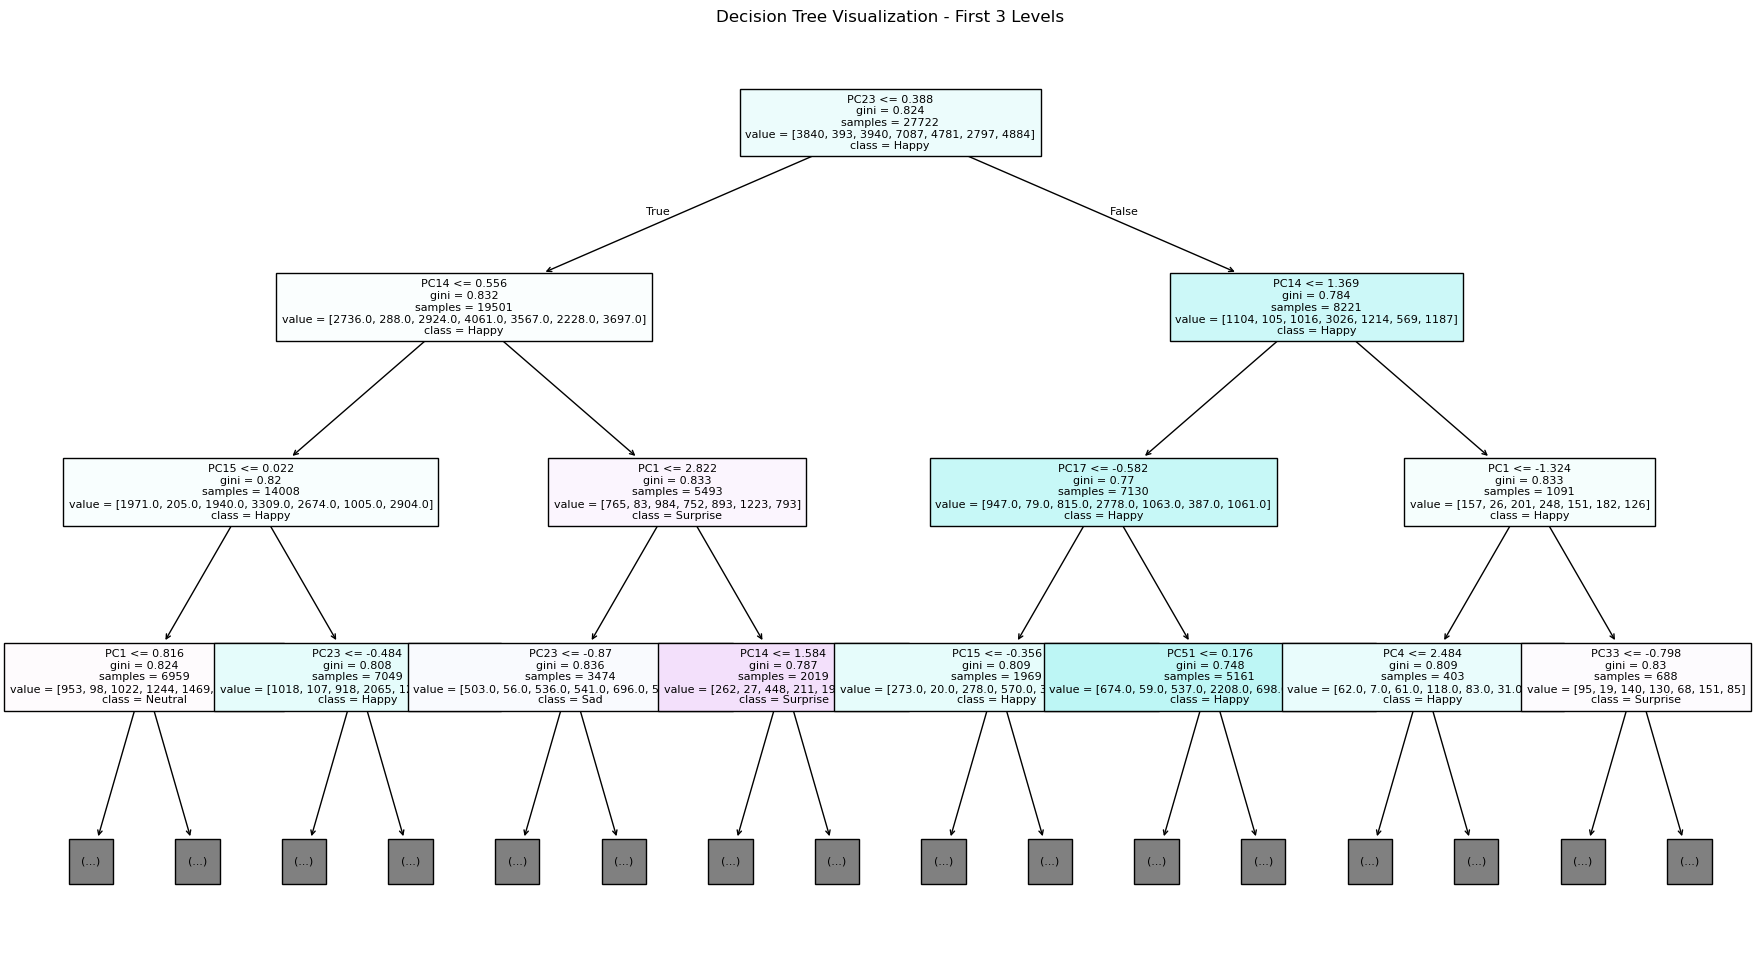

In [59]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    max_depth=3,
    filled=True,
    feature_names=[
        f"PC{i+1}" for i in range(X_train_pca.shape[1])
    ],
    class_names=emotion_names,
    fontsize=8
)

plt.title(
    "Decision Tree Visualization - First 3 Levels"
)

plt.show()

Observation: The Decision Tree classifier was able to classify the seven emotion classes using the reduced PCA features. The confusion matrix shows which emotions are correctly classified and which emotions are frequently confused with each other.

SVC (Support Vector Classifier)

In [39]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Use a smaller subset because SVC is computationally expensive
X_train_svc = X_train_pca[:8000]
y_train_svc = y_train[:8000]

results = []

for kernel in ["linear", "rbf"]:
    
    for C in [0.1, 1.0]:
        
        print("Training:", kernel, "C =", C)
        
        model = SVC(
            C=C,
            kernel=kernel,
            random_state=42
        )
        
        model.fit(X_train_svc, y_train_svc)
        
        pred = model.predict(X_test_pca)
        
        accuracy = accuracy_score(y_test, pred)
        
        results.append({
            "Kernel": kernel,
            "C": C,
            "Accuracy": accuracy
        })

results_df = pd.DataFrame(results)

results_df

Training: linear C = 0.1
Training: linear C = 1.0
Training: rbf C = 0.1
Training: rbf C = 1.0


,Kernel,C,Accuracy
0,linear,0.1,0.361853
1,linear,1.0,0.362141
2,rbf,0.1,0.278459
3,rbf,1.0,0.381619


In [41]:
best_svc = results_df.loc[results_df["Accuracy"].idxmax()]

print("Best Kernel:", best_svc["Kernel"])
print("Best C:", best_svc["C"])
print("Best Accuracy:", best_svc["Accuracy"])

Best Kernel: rbf
Best C: 1.0
Best Accuracy: 0.38161881402395037


In [44]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

best_kernel = best_svc["Kernel"]
best_C = float(best_svc["C"])

svc_model = SVC(
    C=best_C,
    kernel=best_kernel,
    random_state=42
)

svc_model.fit(X_train_svc, y_train_svc)

y_pred_svc = svc_model.predict(X_test_pca)

svc_accuracy = accuracy_score(y_test, y_pred_svc)
svc_f1 = f1_score(y_test, y_pred_svc, average="weighted")

print("SVC training completed!")
print("SVC Accuracy:", svc_accuracy)
print("SVC Weighted F1:", svc_f1)

SVC training completed!
SVC Accuracy: 0.38161881402395037
SVC Weighted F1: 0.3475393821752044


In [48]:
from sklearn.metrics import classification_report

print("SVC - Classification Report\n")

print(classification_report(
    y_test,
    y_pred_svc,
    target_names=emotion_names,
    zero_division=0
))

SVC - Classification Report

              precision    recall  f1-score   support

       Angry       0.29      0.11      0.16       960
     Disgust       0.00      0.00      0.00        98
        Fear       0.30      0.11      0.16       985
       Happy       0.42      0.71      0.53      1772
         Sad       0.32      0.39      0.35      1196
    Surprise       0.48      0.37      0.42       699
     Neutral       0.36      0.37      0.37      1221

    accuracy                           0.38      6931
   macro avg       0.31      0.29      0.28      6931
weighted avg       0.36      0.38      0.35      6931



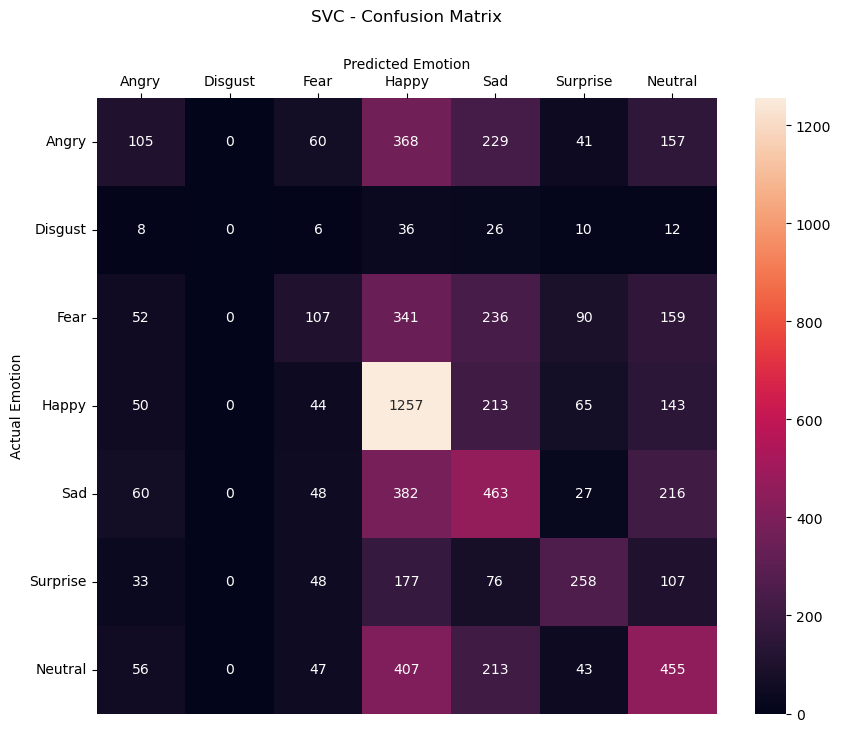

In [49]:
from sklearn.metrics import confusion_matrix

cm_svc = confusion_matrix(y_test, y_pred_svc)

emotion_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt="d",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.xlabel("Predicted Emotion")
plt.gca().xaxis.set_label_position("top")

plt.ylabel("Actual Emotion")

plt.title(
    "SVC - Confusion Matrix",
    pad=55
)

plt.show()

Observation: SVC was able to classify the seven emotion classes using the PCA-reduced features. The confusion matrix shows that some visually similar emotions are more difficult to distinguish, resulting in misclassifications between certain classes.

In [60]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes",
        "Decision Tree",
        "SVC"
    ],
    "Accuracy": [
        lr_accuracy,
        knn_accuracy,
        gnb_accuracy,
        dt_accuracy,
        svc_accuracy
    ],
    "Weighted F1": [
        lr_f1,
        knn_f1,
        gnb_f1,
        dt_f1,
        svc_f1
    ]
})

comparison

,Model,Accuracy,Weighted F1
0,Logistic Regression,0.365171,0.333871
1,KNN,0.326360,0.321631
2,Gaussian Naive Bayes,0.318424,0.301253
3,Decision Tree,0.296061,0.246264
4,SVC,0.381619,0.347539
